## IMPORTING PACKAGES:

In [233]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [234]:
from sklearn.impute import SimpleImputer

## FUNCTION FOR CLEANING TEST:

In [ ]:
def clean(data):
    df = data.copy()

    df= df.drop(columns='id')
    df = df.drop_duplicates()


    mask = df['airline'].isna() & df['flight'].str.startswith(("6.00E", "0.00E"))
    df.loc[mask, 'airline'] = 'Indigo'

    codes = {'UK': 'Vistara', 'AI': 'Air_India', 'G8': 'GO_FIRST',
            'I5': 'AirAsia', 'SG': 'SpiceJet'}

    prefix = df['flight'].str.split('-').str[0]
    df['airline'] = df['airline'].fillna(prefix.map(codes))

    mask = df['stops'].isna() & ~df['flight'].str.startswith(("6.00E", "0.00E"))
    df.loc[mask, 'stops'] = df.groupby('flight')['stops'].transform(
    lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)[mask]

    drop = df['stops'].isna() & (df['airline'] != 'Indigo')
    df = df[~drop]

    corrupted = df['flight'].str.startswith(("6.00E", "0.00E"))
    rules = {'stops': 'mode', 'departure': 'mode', 'duration': 'median'}
    for col, how in rules.items():
        if how == 'mode':
                fill = df.groupby('flight')[col].transform(
                lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)
        else:
                fill = df.groupby('flight')[col].transform('median')

        mask = df[col].isna() & ~corrupted
        df.loc[mask, col] = fill[mask]

    keys_d = ['airline', 'source', 'destination', 'class', 'stops']
    mask = df['duration'].isna()
    df.loc[mask, 'duration'] = df.groupby(keys_d)['duration'].transform('median')[mask]
    df = df[~(df['duration'].isna() & df['stops'].isna())]

    keys = ['airline', 'source', 'destination', 'arrival', df['duration'].round()]
    mask = df['departure'].isna()
    df.loc[mask, 'departure'] = df.groupby(keys)['departure'].transform(
    lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)[mask]
    df = df[df['departure'].notna()]

    keys_s = ['airline', 'source', 'destination', 'class', df['duration'].round()]
    mask = df['stops'].isna()
    df.loc[mask, 'stops'] = df.groupby(keys_s)['stops'].transform(
    lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)[mask]
    df = df[df['stops'].notna()]


    df = df.drop(columns='flight')
    return df

## DATASET:

In [235]:
df = pd.read_csv("train.csv").drop(columns='id')
df.head()

,airline,flight,source,departure,stops,arrival,destination,class,duration,days_left,price
0,Vistara,UK-930,Mumbai,Early_Morning,one,Night,Chennai,Business,NaN,40.0,64173
1,Air_India,AI-539,Chennai,Evening,one,Morning,Mumbai,Economy,16.08,26.0,4357
2,SpiceJet,SG-8107,Delhi,Early_Morning,zero,Morning,Chennai,Economy,2.92,25.0,3251
3,NaN,0.00E+00,Hyderabad,Early_Morning,zero,Morning,Bangalore,Economy,1.50,22.0,1776
4,Air_India,AI-569,Chennai,Early_Morning,one,Morning,Bangalore,Economy,4.83,20.0,3584


# IDENTIFY DATATYPES OF DIFFERENT COLUMNS:

In [236]:
print(df.info())
print(df.columns.to_list())

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   airline      35387 non-null  str    
 1   flight       40000 non-null  str    
 2   source       40000 non-null  str    
 3   departure    35208 non-null  str    
 4   stops        37681 non-null  str    
 5   arrival      40000 non-null  str    
 6   destination  40000 non-null  str    
 7   class        40000 non-null  str    
 8   duration     36987 non-null  float64
 9   days_left    35562 non-null  float64
 10  price        40000 non-null  int64  
dtypes: float64(2), int64(1), str(8)
memory usage: 3.4 MB
None
['airline', 'flight', 'source', 'departure', 'stops', 'arrival', 'destination', 'class', 'duration', 'days_left', 'price']


# DESCRIPTIVE STATISTICS:

In [237]:
df.describe()

,duration,days_left,price
count,36987.000000,35562.000000,40000.00000
mean,12.004088,26.197936,20801.49025
std,7.108063,13.469232,22729.14842
min,0.830000,1.000000,1105.00000
25%,6.670000,15.000000,4687.00000
50%,11.080000,26.000000,7353.00000
75%,15.920000,38.000000,42521.00000
max,47.080000,49.000000,114704.00000


In [238]:
df[(df['airline']=='Indigo')&(df["flight"].str.startswith(("6.00E")))].shape[0]

573

In [239]:
print(f"no. of rows with Indigo's corrupted 'flight' cell: {df[df['flight'].str.startswith(("6.00E"))].shape[0]}")
print(f"no. of rows with 0.00E in corrupted 'flight' cell: {df[df["flight"].str.startswith("0.00E")].shape[0]}")

no. of rows with Indigo's corrupted 'flight' cell: 652
no. of rows with 0.00E in corrupted 'flight' cell: 5270


In [240]:
print(df.duplicated().sum())
df = df.drop_duplicates()

250


# HANDLING MISSING VALUES:

In [241]:
df.isna().sum() #counting the NaN's

airline        4609
flight            0
source            0
departure      4788
stops          2319
arrival           0
destination       0
class             0
duration       3005
days_left      4195
price             0
dtype: int64

In [242]:
mask = df['flight'].str.startswith("6.00E") & (df['airline'] != 'Indigo')
df.loc[mask, 'airline'].value_counts(dropna=True)

Series([], Name: count, dtype: int64)

All '6.00E' corrupted rows are likely to be Indigo, since Indigo's code is 6E which may have not rendered corrected in csv format.

steps taken to rectify:
- filtering out the 6.00E/0.00E corrupted values in flight
- filling those with missing airline with 'Indigo'

In [243]:
# before: how many missing airlines in corrupted rows
mask = df['airline'].isna() & df['flight'].str.startswith(("6.00E", "0.00E"))
print(mask.sum())                       # expect ~686

# fill
df.loc[mask, 'airline'] = 'Indigo'

# after
print(df['airline'].isna().sum())       # remaining missing (intact codes)

686
3923


For non-Indigo missing vlaues, using their codes from 'flight' column:

In [244]:
codes = {'UK': 'Vistara', 'AI': 'Air_India', 'G8': 'GO_FIRST',
         'I5': 'AirAsia', 'SG': 'SpiceJet'}

prefix = df['flight'].str.split('-').str[0]
df['airline'] = df['airline'].fillna(prefix.map(codes))

print(df['airline'].isna().sum())

0


Checking other missing rows for next step:

In [245]:
df.isna().sum()

airline           0
flight            0
source            0
departure      4788
stops          2319
arrival           0
destination       0
class             0
duration       3005
days_left      4195
price             0
dtype: int64

In [246]:

df[df['stops'].isna() & (df['airline'] == 'SpiceJet') & (df['flight']=="SG-8152")]

,airline,flight,source,departure,stops,arrival,destination,class,duration,days_left,price
154,SpiceJet,SG-8152,Mumbai,Early_Morning,NaN,Morning,Kolkata,Economy,25.75,28.0,5289
195,SpiceJet,SG-8152,Mumbai,Early_Morning,NaN,Morning,Kolkata,Economy,25.75,12.0,7728
4612,SpiceJet,SG-8152,Mumbai,Early_Morning,NaN,Night,Kolkata,Economy,15.67,28.0,5289
27024,SpiceJet,SG-8152,Delhi,Morning,NaN,Night,Kolkata,Economy,11.25,37.0,6129


In [247]:
df[(df['flight']=='SG-8152') & (df['stops'].notna())]['stops'].head()

375      one
1259     one
4769     one
5489    zero
8167     one
Name: stops, dtype: str

In [248]:
mask = df['stops'].isna() & ~df['flight'].str.startswith(("6.00E", "0.00E"))

df.loc[mask, 'stops'] = df.groupby('flight')['stops'].transform(
    lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)[mask]

print(df['stops'].isna().sum())
df.isna().sum()

355


airline           0
flight            0
source            0
departure      4788
stops           355
arrival           0
destination       0
class             0
duration       3005
days_left      4195
price             0
dtype: int64

In [249]:
drop = df['stops'].isna() & (df['airline'] != 'Indigo')
df = df[~drop]
df['stops'].isna().sum()


np.int64(348)

In [250]:
corrupted = df['flight'].str.startswith(("6.00E", "0.00E"))

rules = {'stops': 'mode', 'departure': 'mode', 'duration': 'median'}

for col, how in rules.items():
    if how == 'mode':
        fill = df.groupby('flight')[col].transform(
            lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)
    else:
        fill = df.groupby('flight')[col].transform('median')

    mask = df[col].isna() & ~corrupted
    df.loc[mask, col] = fill[mask]


In [251]:
imp = SimpleImputer(strategy='median', add_indicator=True)

df['days_left_missing'] = df['days_left'].isna().astype(int)
df['days_left'] = df['days_left'].fillna(df['days_left'].median())

df.isna().sum()

airline                0
flight                 0
source                 0
departure            696
stops                348
arrival                0
destination            0
class                  0
duration             484
days_left              0
price                  0
days_left_missing      0
dtype: int64

In [252]:
keys_d = ['airline', 'source', 'destination', 'class', 'stops']
mask = df['duration'].isna()
df.loc[mask, 'duration'] = df.groupby(keys_d)['duration'].transform('median')[mask]

df.isna().sum()

airline                0
flight                 0
source                 0
departure            696
stops                348
arrival                0
destination            0
class                  0
duration              26
days_left              0
price                  0
days_left_missing      0
dtype: int64

In [253]:
df = df[~(df['duration'].isna() & df['stops'].isna())]

df.isna().sum()

airline                0
flight                 0
source                 0
departure            692
stops                322
arrival                0
destination            0
class                  0
duration               0
days_left              0
price                  0
days_left_missing      0
dtype: int64

In [254]:
keys = ['airline', 'source', 'destination', 'arrival', df['duration'].round()]

mask = df['departure'].isna()
df.loc[mask, 'departure'] = df.groupby(keys)['departure'].transform(
    lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)[mask]


df['departure'].isna().sum()

np.int64(27)

In [255]:
df = df[df['departure'].notna()]
df.isna().sum()

airline                0
flight                 0
source                 0
departure              0
stops                322
arrival                0
destination            0
class                  0
duration               0
days_left              0
price                  0
days_left_missing      0
dtype: int64

Now, rerunning mask and imputing for stops now that we have all values filled in for the features it depended on for imputation before:


In [256]:
keys_s = ['airline', 'source', 'destination', 'class', df['duration'].round()]
mask = df['stops'].isna()
df.loc[mask, 'stops'] = df.groupby(keys_s)['stops'].transform(
    lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)[mask]

df.isna().sum()


airline              0
flight               0
source               0
departure            0
stops                1
arrival              0
destination          0
class                0
duration             0
days_left            0
price                0
days_left_missing    0
dtype: int64

In [257]:
df = df[df['stops'].notna()]
df.isna().sum()

airline              0
flight               0
source               0
departure            0
stops                0
arrival              0
destination          0
class                0
duration             0
days_left            0
price                0
days_left_missing    0
dtype: int64

# HANDLING DUPLICATES:

Handled this at the start, before imputation itself.

# HANDLING OUTLIERS:

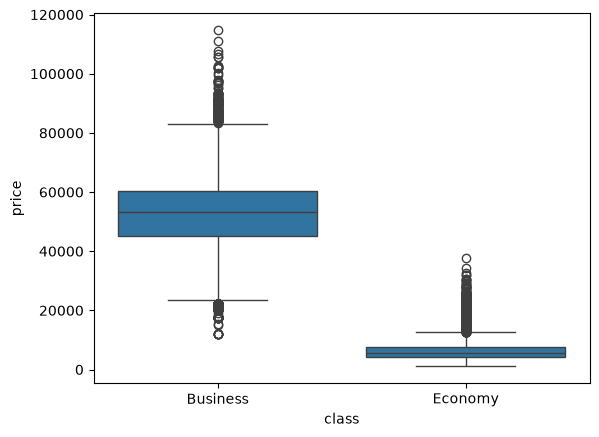

In [260]:
sns.boxplot(data=df, x='class', y='price')
plt.show()

In this prediction project, since prices are sensitive and volatile, I will not be dropping "outliers" even if beyond 1.5*IQR, since they possess informative features that may help with better prediction.

In [261]:
df[(df['class'] == 'Economy') & (df['price'] > 13000)]['days_left'].describe()

count    1784.000000
mean       10.841928
std         8.967175
min         1.000000
25%         4.000000
50%         9.000000
75%        13.000000
max        49.000000
Name: days_left, dtype: float64

These seem like normal data for last minute fares. Hence stronger the argument to not drop outliers.

# VISUALIZATIONS:

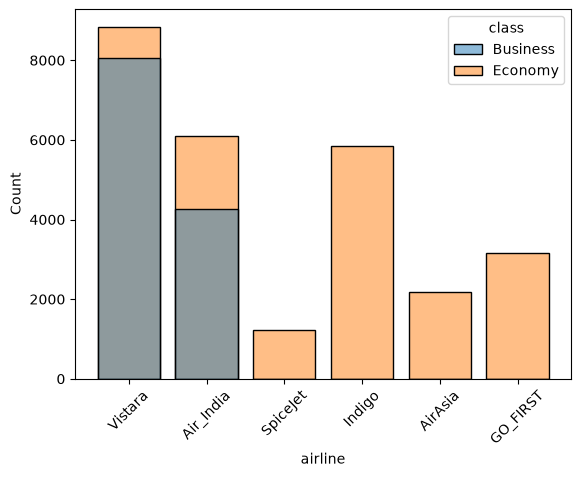

In [258]:
sns.histplot(data=df, x='airline', shrink=0.8,hue='class')
plt.xticks(rotation=45)
plt.show()

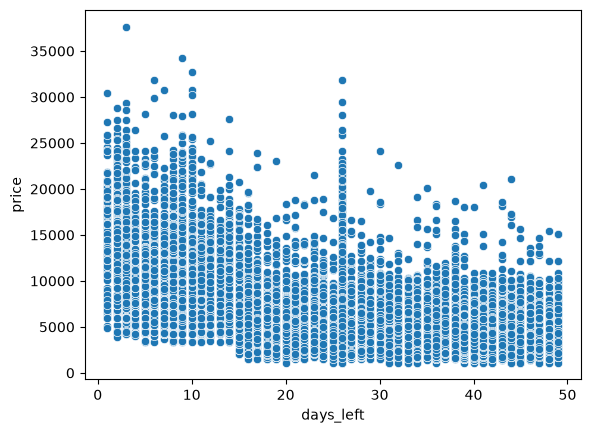

In [259]:
sns.scatterplot(data=df[df['class'] == 'Economy'], x='days_left', y='price')
plt.show()

# SCALING AND ENCODING:

# MODEL BUILDING:

# HYPERPARAMETER TUNING:

# COMPARISONS: